# RetailMind AI - Day 8: Segmentation, Background Removal & Grad-CAM

Corrected Day 8 notebook for the existing RetailMind project. It implements product segmentation/background removal, OpenCV catalog compositing, Grad-CAM explainability using the saved Day 7 MobileNetV2 classifier, and a packaged end-to-end CV interface.

This version fixes the nested-MobileNetV2 Grad-CAM gradient issue from the previous notebook.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import json
import cv2
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display

tf.keras.utils.set_random_seed(42)
current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'notebooks' else current
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUT_DIR = MODELS_DIR / 'day8_cv_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_PATH = PROJECT_ROOT / 'data' / 'product_images' / 'sample.jpg'
CLASSIFIER_PATH = MODELS_DIR / 'catalog_transfer_mobilenetv2.keras'
assert IMAGE_PATH.exists(), f'Missing image: {IMAGE_PATH}'
assert CLASSIFIER_PATH.exists(), f'Missing classifier: {CLASSIFIER_PATH}'
print('Project root:', PROJECT_ROOT)
print('Input image:', IMAGE_PATH)
print('TensorFlow:', tf.__version__)
print('OpenCV:', cv2.__version__)

I0000 00:00:1794457138.375018 2022245 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794457138.422093 2022245 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794457140.048420 2022245 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Project root: /home/jovyan/work/RetailMind
Input image: /home/jovyan/work/RetailMind/data/product_images/sample.jpg
TensorFlow: 2.21.0
OpenCV: 5.0.0


## 2. Original image

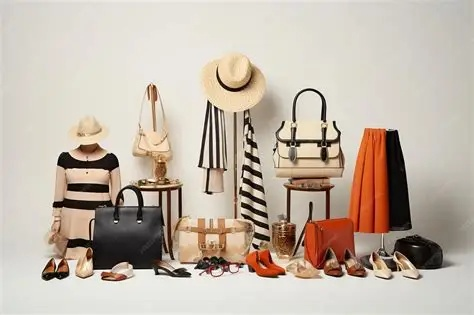

In [2]:
display(Image(filename=str(IMAGE_PATH)))

## 3. Segment the foreground with OpenCV GrabCut

GrabCut provides an explicit foreground/background mask without training a large U-Net on the CPU-only work laptop. Morphological cleanup improves the mask edges.

In [3]:
image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise FileNotFoundError(IMAGE_PATH)
h, w = image_bgr.shape[:2]
mask = np.zeros((h, w), np.uint8)
bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)
mx, my = max(5, int(w * 0.03)), max(5, int(h * 0.03))
rect = (mx, my, w - 2 * mx, h - 2 * my)
cv2.grabCut(image_bgr, mask, rect, bg_model, fg_model, 5, cv2.GC_INIT_WITH_RECT)
binary_mask = np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 255, 0).astype('uint8')
kernel = np.ones((5, 5), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
mask_path = OUTPUT_DIR / 'product_mask.png'
cv2.imwrite(str(mask_path), binary_mask)
print('Saved:', mask_path)

Saved: /home/jovyan/work/RetailMind/models/day8_cv_outputs/product_mask.png


## 4. Display segmentation mask

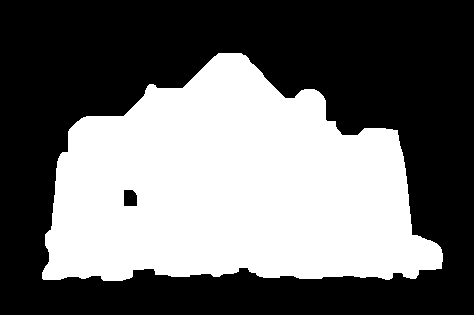

In [4]:
display(Image(filename=str(mask_path)))

## 5. Background removal and clean catalog compositing

Transparent: /home/jovyan/work/RetailMind/models/day8_cv_outputs/product_transparent.png
White catalog: /home/jovyan/work/RetailMind/models/day8_cv_outputs/clean_catalog_white.jpg


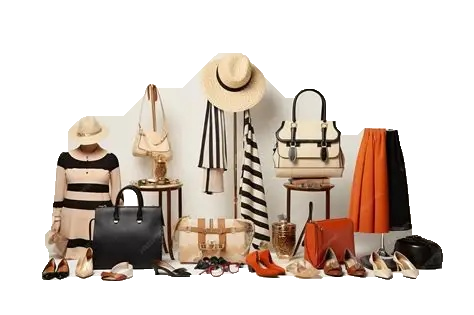

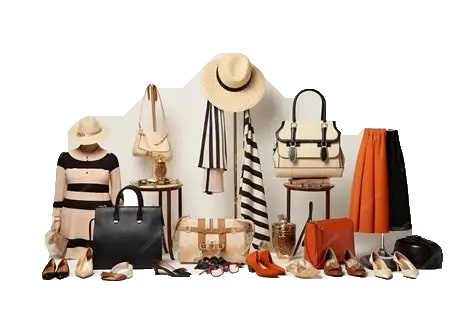

In [5]:
image_bgra = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2BGRA)
image_bgra[:, :, 3] = binary_mask
transparent_path = OUTPUT_DIR / 'product_transparent.png'
cv2.imwrite(str(transparent_path), image_bgra)
alpha = (binary_mask.astype(np.float32) / 255.0)[..., np.newaxis]
white = np.full_like(image_bgr, 255)
catalog_bgr = (image_bgr * alpha + white * (1.0 - alpha)).astype(np.uint8)
catalog_path = OUTPUT_DIR / 'clean_catalog_white.jpg'
cv2.imwrite(str(catalog_path), catalog_bgr)
print('Transparent:', transparent_path)
print('White catalog:', catalog_path)
display(Image(filename=str(transparent_path)))
display(Image(filename=str(catalog_path)))

## 6. Load the Day 7 MobileNetV2 classifier

In [6]:
classifier = keras.models.load_model(CLASSIFIER_PATH)
classifier_name = 'MobileNetV2 transfer classifier'
print('Loaded:', classifier_name)
print('Input:', classifier.input_shape)
print('Output:', classifier.output_shape)
for i, layer in enumerate(classifier.layers):
    print(i, layer.name, type(layer).__name__)

E0000 00:00:1794457143.481144 2022245 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Loaded: MobileNetV2 transfer classifier
Input: (None, 64, 64, 3)
Output: (None, 10)
0 input_layer_1 InputLayer
1 mobilenetv2_1.00_224 Functional
2 global_average_pooling2d GlobalAveragePooling2D
3 dropout Dropout
4 dense Dense


## 7. Prepare image and make classification prediction

In [7]:
class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
def prepare_for_classifier(path):
    bgr = cv2.imread(str(path))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    target_h, target_w = int(classifier.input_shape[1]), int(classifier.input_shape[2])
    resized = cv2.resize(rgb, (target_w, target_h)).astype('float32')
    resized = keras.applications.mobilenet_v2.preprocess_input(resized)
    return np.expand_dims(resized, 0), rgb
model_input, original_rgb = prepare_for_classifier(IMAGE_PATH)
prediction = classifier.predict(model_input, verbose=0)[0]
predicted_index = int(np.argmax(prediction))
predicted_score = float(np.max(prediction))
predicted_label = class_names[predicted_index]
print('Predicted class:', predicted_label)
print('Prediction score:', round(predicted_score, 4))

Predicted class: Dress
Prediction score: 0.3699


## 8. Identify the nested MobileNetV2 backbone and Grad-CAM feature layer

In [8]:
nested_backbone = None
for layer in classifier.layers:
    if isinstance(layer, keras.Model):
        nested_backbone = layer
        break
if nested_backbone is None:
    raise ValueError('Nested MobileNetV2 backbone was not found.')
last_conv_name = 'out_relu'
feature_layer = nested_backbone.get_layer(last_conv_name)
print('Backbone:', nested_backbone.name)
print('Grad-CAM feature layer:', last_conv_name)
print('Feature shape:', feature_layer.output.shape)

Backbone: mobilenetv2_1.00_224
Grad-CAM feature layer: out_relu
Feature shape: (None, 2, 2, 1280)


## 9. Generate corrected MobileNetV2 Grad-CAM heatmap

The previous notebook broke the gradient connection by running backbone features and class predictions through separate graphs. This implementation keeps the classification tail connected to the MobileNetV2 backbone output inside one GradientTape.

In [9]:
backbone_index = classifier.layers.index(nested_backbone)
tail_input = keras.Input(shape=tuple(nested_backbone.output.shape[1:]))
x = tail_input
for layer in classifier.layers[backbone_index + 1:]:
    x = layer(x)
classifier_tail = keras.Model(tail_input, x)

with tf.GradientTape() as tape:
    backbone_output = nested_backbone(model_input, training=False)
    tape.watch(backbone_output)
    predictions = classifier_tail(backbone_output, training=False)
    class_score = predictions[:, predicted_index]

grads = tape.gradient(class_score, backbone_output)
if grads is None:
    raise RuntimeError('Grad-CAM gradient could not be calculated.')
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
feature_maps = backbone_output[0]
heatmap = tf.reduce_sum(feature_maps * pooled_grads, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()
print('Grad-CAM heatmap shape:', heatmap.shape)

Grad-CAM heatmap shape: (2, 2)


## 10. Overlay Grad-CAM on the product image

Saved: /home/jovyan/work/RetailMind/models/day8_cv_outputs/gradcam_overlay.jpg


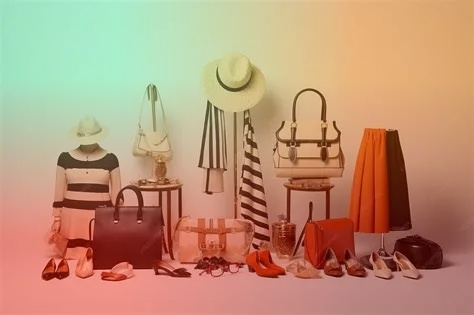

In [10]:
heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
heatmap_color = cv2.resize(heatmap_color, (w, h))
overlay_bgr = cv2.addWeighted(image_bgr, 0.60, heatmap_color, 0.40, 0)
gradcam_path = OUTPUT_DIR / 'gradcam_overlay.jpg'
cv2.imwrite(str(gradcam_path), overlay_bgr)
print('Saved:', gradcam_path)
display(Image(filename=str(gradcam_path)))

## 11. Package classification + detection + segmentation + explainability

In [11]:
YOLO_JSON = MODELS_DIR / 'day7_yolo_results.json'
detections = []
if YOLO_JSON.exists():
    with open(YOLO_JSON) as f:
        day7_detection = json.load(f)
    detections = day7_detection.get('detections', [])
cv_result = {
    'classification': {'class': predicted_label, 'score': round(predicted_score, 4)},
    'detections': detections,
    'segmentation_mask': str(mask_path.relative_to(PROJECT_ROOT)),
    'transparent_product': str(transparent_path.relative_to(PROJECT_ROOT)),
    'clean_catalog_image': str(catalog_path.relative_to(PROJECT_ROOT)),
    'gradcam_overlay': str(gradcam_path.relative_to(PROJECT_ROOT))
}
def retailmind_cv():
    return cv_result
print(json.dumps(retailmind_cv(), indent=2))

{
  "classification": {
    "class": "Dress",
    "score": 0.3699
  },
  "detections": [
    {
      "class": "suitcase",
      "confidence": 0.5319,
      "box": [
        90.1,
        204.3,
        164.5,
        272.1
      ]
    }
  ],
  "segmentation_mask": "models/day8_cv_outputs/product_mask.png",
  "transparent_product": "models/day8_cv_outputs/product_transparent.png",
  "clean_catalog_image": "models/day8_cv_outputs/clean_catalog_white.jpg",
  "gradcam_overlay": "models/day8_cv_outputs/gradcam_overlay.jpg"
}


## 12. Save the packaged CV-module manifest

In [12]:
manifest = {
    'module': 'RetailMind CV Phase 2',
    'input_image': str(IMAGE_PATH.relative_to(PROJECT_ROOT)),
    'classifier': classifier_name,
    'capabilities': ['classification','object detection','segmentation/background removal','OpenCV catalog compositing','Grad-CAM explainability'],
    'result': cv_result
}
manifest_path = MODELS_DIR / 'day8_cv_module.json'
with open(manifest_path, 'w') as f:
    json.dump(manifest, f, indent=2)
print('Saved:', manifest_path)

Saved: /home/jovyan/work/RetailMind/models/day8_cv_module.json


## 13. Verify Day 8 artifacts

In [13]:
required = [mask_path, transparent_path, catalog_path, gradcam_path, manifest_path]
for path in required:
    print(('OK' if path.exists() else 'MISSING'), '-', path.relative_to(PROJECT_ROOT))
assert all(path.exists() for path in required), 'A Day 8 artifact is missing.'
print('Day 8 completed successfully.')

OK - models/day8_cv_outputs/product_mask.png
OK - models/day8_cv_outputs/product_transparent.png
OK - models/day8_cv_outputs/clean_catalog_white.jpg
OK - models/day8_cv_outputs/gradcam_overlay.jpg
OK - models/day8_cv_module.json
Day 8 completed successfully.


## 14. README-ready summary

In [14]:
foreground_ratio = np.count_nonzero(binary_mask) / binary_mask.size
print('DAY 8 - SEGMENTATION & END-TO-END CV')
print('-' * 60)
print('Input:', IMAGE_PATH.relative_to(PROJECT_ROOT))
print('Segmentation: OpenCV GrabCut + morphology')
print('Foreground ratio:', f'{foreground_ratio:.3f}')
print('Classifier:', classifier_name)
print('Predicted class:', predicted_label)
print('Prediction score:', f'{predicted_score:.4f}')
print('Grad-CAM feature layer:', last_conv_name)
print('Clean catalog image:', catalog_path.relative_to(PROJECT_ROOT))
print('Grad-CAM overlay:', gradcam_path.relative_to(PROJECT_ROOT))
print('CV manifest:', manifest_path.relative_to(PROJECT_ROOT))

DAY 8 - SEGMENTATION & END-TO-END CV
------------------------------------------------------------
Input: data/product_images/sample.jpg
Segmentation: OpenCV GrabCut + morphology
Foreground ratio: 0.424
Classifier: MobileNetV2 transfer classifier
Predicted class: Dress
Prediction score: 0.3699
Grad-CAM feature layer: out_relu
Clean catalog image: models/day8_cv_outputs/clean_catalog_white.jpg
Grad-CAM overlay: models/day8_cv_outputs/gradcam_overlay.jpg
CV manifest: models/day8_cv_module.json


## Requirement coverage

- Explicit segmentation mask and background removal
- OpenCV clean catalog compositing on a uniform white background
- Grad-CAM explainability for the Day 7 MobileNetV2 classifier
- Previous YOLO detection metadata linked into the CV result
- Classification + detection + segmentation + explainability packaged into one interface/manifest
- Saved and verified artifacts

### Business value
The module produces cleaner catalog imagery and adds visual evidence for classifier decisions, improving catalog consistency and model reviewability.

### Open blocker
GrabCut is a lightweight segmentation prototype. Complex retail scenes and precise product boundaries would benefit from a trained U-Net or pretrained semantic/instance segmentation model in a GPU-backed environment.